In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
FILE = "Water Quality.csv"  # Change to full path if required.

def locate_csv(filename):
    p = Path(filename)
    if p.is_file(): return p.resolve()
    for root in [Path.cwd(), Path.home()/"Desktop", Path.home()/"Downloads", Path.home()/"Documents"]:
        if root.exists():
            try:
                for item in root.rglob("*"):
                    if item.is_file() and item.name.lower() == filename.lower(): return item.resolve()
            except (OSError, PermissionError): pass
    try:
        import tkinter as tk
        from tkinter import filedialog
        w=tk.Tk(); w.withdraw(); w.attributes("-topmost", True)
        chosen=filedialog.askopenfilename(title="Select Water Quality.csv",filetypes=[("CSV","*.csv")])
        w.destroy()
        return Path(chosen) if chosen else None
    except Exception: return None

csv_path=locate_csv(FILE)
if csv_path is None: raise FileNotFoundError("Put Water Quality.csv beside the notebook or set FILE to its full path.")
df=pd.read_csv(csv_path, low_memory=False); df.columns=df.columns.str.strip()
required={"MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"}
if not required.issubset(df.columns): raise ValueError(f"Missing columns: {sorted(required-set(df.columns))}")
df["ActivityStartDate"]=pd.to_datetime(df["ActivityStartDate"], errors="coerce")
df["ResultValue"]=pd.to_numeric(df["ResultValue"], errors="coerce")
df=df.dropna(subset=["MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"]).copy()
for c in ["MonitoringLocationID","CharacteristicName"]: df[c]=df[c].astype(str).str.strip()
if "ResultUnit" not in df: df["ResultUnit"]="UNSPECIFIED"
df["ResultUnit"]=df["ResultUnit"].fillna("UNSPECIFIED").astype(str).str.strip()
print("Loaded:", csv_path, "| rows:",len(df),"| locations:",df.MonitoringLocationID.nunique(),"| parameters:",df.CharacteristicName.nunique())

Loaded: C:\Users\YASH\Desktop\water\Water Quality.csv | rows: 229916 | locations: 58 | parameters: 83


In [2]:
df["SampleDate"]=df.ActivityStartDate.dt.floor("D")
daily=(df.groupby(["MonitoringLocationID","CharacteristicName","ResultUnit","SampleDate"])
       .agg(ResultValue=("ResultValue","median"),ReadingCount=("ResultValue","size")).reset_index()
       .sort_values(["MonitoringLocationID","CharacteristicName","ResultUnit","SampleDate"]))
print("Daily records:",len(daily)); display(daily.head())

Daily records: 223507


,MonitoringLocationID,CharacteristicName,ResultUnit,SampleDate,ResultValue,ReadingCount
0,NB01BR0006,"Alkalinity, total",mg/L,2001-04-26,1.8,1
1,NB01BR0006,"Alkalinity, total",mg/L,2001-05-22,2.8,1
2,NB01BR0006,"Alkalinity, total",mg/L,2001-06-19,8.4,1
3,NB01BR0006,"Alkalinity, total",mg/L,2001-07-18,20.2,1
4,NB01BR0006,"Alkalinity, total",mg/L,2001-08-20,75.6,1


In [3]:
keys=["MonitoringLocationID","CharacteristicName","ResultUnit"]
def feature_series(g):
    g=g.sort_values("SampleDate").copy(); x=g.ResultValue.astype(float)
    med=x.median(); mad=np.median(np.abs(x-med)); scale=1.4826*mad
    if not np.isfinite(scale) or scale<=0: scale=x.std(ddof=0)
    if not np.isfinite(scale) or scale<=0: scale=1.0
    g["RobustZ"]=(x-med)/scale
    win=max(5,min(15,int(np.sqrt(len(g)))))
    roll=x.rolling(win,center=True,min_periods=max(3,win//3)).median().fillna(med)
    g["RollingMedianDeviation"]=(x-roll)/scale
    g["TimePosition"]=np.linspace(0,1,len(g)) if len(g)>1 else 0.0
    return g
parts=[feature_series(g) for _,g in daily.groupby(keys,dropna=False) if len(g)>=8]
if not parts: raise ValueError("No location/parameter/unit series has at least 8 daily records.")
analysis_df=pd.concat(parts,ignore_index=True)
FEATURES=["RobustZ","RollingMedianDeviation","TimePosition"]
print("Model records:",len(analysis_df)); display(analysis_df.head())

Model records: 221204


,MonitoringLocationID,CharacteristicName,ResultUnit,SampleDate,ResultValue,ReadingCount,RobustZ,RollingMedianDeviation,TimePosition
0,NB01BR0006,"Alkalinity, total",mg/L,2001-04-26,1.8,1,-0.667251,-0.120660,0.000000
1,NB01BR0006,"Alkalinity, total",mg/L,2001-05-22,2.8,1,-0.546591,-0.337849,0.038462
2,NB01BR0006,"Alkalinity, total",mg/L,2001-06-19,8.4,1,0.129106,0.000000,0.076923
3,NB01BR0006,"Alkalinity, total",mg/L,2001-07-18,20.2,1,1.552897,1.423791,0.115385
4,NB01BR0006,"Alkalinity, total",mg/L,2001-08-20,75.6,1,8.237475,6.684577,0.153846


In [4]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
X=analysis_df[FEATURES].replace([np.inf,-np.inf],np.nan)
X=SimpleImputer(strategy="median").fit_transform(X)
Xscaled=StandardScaler().fit_transform(X)
contaminations=[.01,.025,.05,.10]
if_flags={}; tuning=[]
for c in contaminations:
    model=IsolationForest(n_estimators=300,contamination=c,random_state=42,n_jobs=-1)
    labels=model.fit_predict(Xscaled); flags=labels==-1
    name=f"IF_contamination_{c}"; if_flags[name]=flags
    tuning.append({"Method":"IsolationForest","Setting":name,"FlaggedCount":int(flags.sum()),"FlaggedPercent":100*flags.mean()})
display(pd.DataFrame(tuning))

,Method,Setting,FlaggedCount,FlaggedPercent
0,IsolationForest,IF_contamination_0.01,2213,1.000434
1,IsolationForest,IF_contamination_0.025,5531,2.500407
2,IsolationForest,IF_contamination_0.05,11061,5.000362
3,IsolationForest,IF_contamination_0.1,22121,10.000271


In [7]:
flagsets={**if_flags,**db_flags}
flag_summary=pd.DataFrame([{"Configuration":k,"FlaggedCount":int(v.sum()),"FlaggedPercent":100*v.mean()} for k,v in flagsets.items()]).sort_values("FlaggedPercent")
display(flag_summary)
SELECT_IF="IF_contamination_0.025"
SELECT_DB="DBSCAN_eps_1.0_min_5"
if SELECT_IF not in if_flags or SELECT_DB not in db_flags: raise ValueError("Review configuration names above.")
analysis_df["IsolationForest_Anomaly"]=if_flags[SELECT_IF]
analysis_df["DBSCAN_Anomaly"]=db_flags[SELECT_DB]
analysis_df["BothMethods_Flag"]=analysis_df.IsolationForest_Anomaly & analysis_df.DBSCAN_Anomaly
analysis_df["EitherMethod_Flag"]=analysis_df.IsolationForest_Anomaly | analysis_df.DBSCAN_Anomaly
print("Both methods:",int(analysis_df.BothMethods_Flag.sum()),"| either method:",int(analysis_df.EitherMethod_Flag.sum()))

,Configuration,FlaggedCount,FlaggedPercent
8,DBSCAN_eps_1.0_min_5,791,0.357588
9,DBSCAN_eps_1.0_min_10,1032,0.466538
6,DBSCAN_eps_0.8_min_5,1058,0.478292
7,DBSCAN_eps_0.8_min_10,1379,0.623406
4,DBSCAN_eps_0.5_min_5,1817,0.821414
0,IF_contamination_0.01,2213,1.000434
5,DBSCAN_eps_0.5_min_10,2541,1.148713
1,IF_contamination_0.025,5531,2.500407
2,IF_contamination_0.05,11061,5.000362
3,IF_contamination_0.1,22121,10.000271


Both methods: 777 | either method: 5545


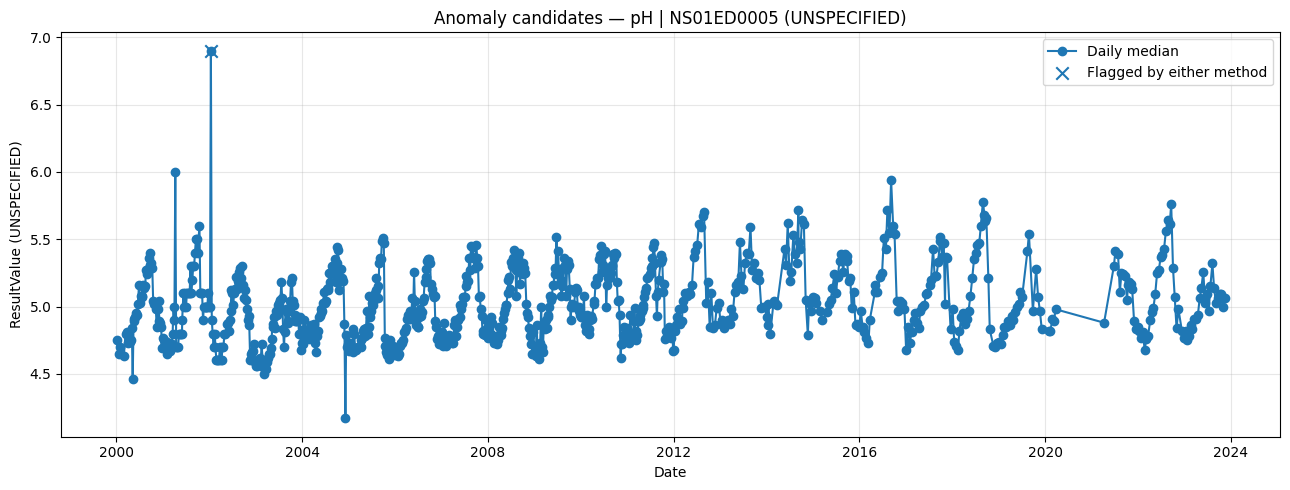

In [8]:
sizes=analysis_df.groupby(keys).size().sort_values(ascending=False)
chosen=tuple(map(str,sizes.index[0]))
mask=np.ones(len(analysis_df),dtype=bool)
for col,val in zip(keys,chosen): mask &= analysis_df[col].astype(str).to_numpy()==val
g=analysis_df.loc[mask].sort_values("SampleDate")
plt.figure(figsize=(13,5)); plt.plot(g.SampleDate,g.ResultValue,marker="o",label="Daily median")
flag=g.EitherMethod_Flag
plt.scatter(g.loc[flag,"SampleDate"],g.loc[flag,"ResultValue"],marker="x",s=80,label="Flagged by either method")
plt.title(f"Anomaly candidates — {chosen[1]} | {chosen[0]} ({chosen[2]})")
plt.xlabel("Date"); plt.ylabel(f"ResultValue ({chosen[2]})"); plt.legend(); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()

In [9]:
outdir=csv_path.parent/"task3_anomaly_outputs"; outdir.mkdir(exist_ok=True)
analysis_df.to_csv(outdir/"all_records_with_anomaly_flags.csv",index=False)
review=analysis_df[analysis_df.EitherMethod_Flag].sort_values(["MonitoringLocationID","CharacteristicName","SampleDate"])
review.to_csv(outdir/"anomaly_review_candidates.csv",index=False)
flag_summary.to_csv(outdir/"configuration_flag_summary.csv",index=False)
pd.DataFrame(tuning).to_csv(outdir/"model_tuning_summary.csv",index=False)
print("Saved outputs:",outdir,"| review candidates:",len(review)); display(review.head(25))

Saved outputs: C:\Users\YASH\Desktop\water\task3_anomaly_outputs | review candidates: 5545


,MonitoringLocationID,CharacteristicName,ResultUnit,SampleDate,ResultValue,ReadingCount,RobustZ,RollingMedianDeviation,TimePosition,IsolationForest_Anomaly,DBSCAN_Anomaly,BothMethods_Flag,EitherMethod_Flag
4,NB01BR0006,"Alkalinity, total",mg/L,2001-08-20,75.600,1,8.237475,6.684577,0.153846,True,False,False,True
16,NB01BR0006,"Alkalinity, total",mg/L,2018-07-31,71.600,1,7.754834,3.945590,0.615385,True,False,False,True
146,NB01BR0006,Apparent color,TCU,2023-07-19,980.000,1,5.114271,4.002473,0.981481,True,False,False,True
174,NB01BR0006,Arsenic,ug/L,2021-07-29,8.830,1,7.908948,7.647855,0.787879,True,False,False,True
177,NB01BR0006,Arsenic,ug/L,2022-07-26,7.050,1,5.972507,5.711414,0.878788,True,False,False,True
180,NB01BR0006,Arsenic,ug/L,2023-07-19,9.880,1,9.051231,8.779259,0.969697,True,False,False,True
257,NB01BR0006,Bismuth,ug/L,2023-07-19,0.023,1,7.194568,7.419398,0.888889,True,False,False,True
260,NB01BR0006,Boron,ug/L,2018-07-31,13.000,1,10.004946,6.744908,0.071429,True,False,False,True
261,NB01BR0006,Boron,ug/L,2018-10-09,10.000,1,6.632492,6.744908,0.142857,True,False,False,True
302,NB01BR0006,Calcium,mg/L,2001-08-20,21.400,1,6.782379,6.332719,0.129630,True,False,False,True
